**NASA EMIT Hyperspectral Image Analysis**

In [41]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import os

# Path to  new dataset
base = "/kaggle/input/datasets/nikita22102002/nasa-emit-hyperspectral-dataset-february-2026"

# Identify the two files
scene = "20260211T080401_2604206_018"

rfl_files = glob(f"{base}/*RFL*{scene}*.nc")
mask_files = glob(f"{base}/*MASK*{scene}*.nc")

print("RFL files:", rfl_files)
print("MASK files:", mask_files)

assert len(rfl_files) == 1, "RFL file not found or multiple matches!"
assert len(mask_files) == 1, "MASK file not found or multiple matches!"

f = rfl_files[0]
mask_f = mask_files[0]

print("\nSelected RFL:", f)
print("Selected MASK:", mask_f)

RFL files: ['/kaggle/input/datasets/nikita22102002/nasa-emit-hyperspectral-dataset-february-2026/EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc']
MASK files: ['/kaggle/input/datasets/nikita22102002/nasa-emit-hyperspectral-dataset-february-2026/EMIT_L2A_MASK_001_20260211T080401_2604206_018.nc']

Selected RFL: /kaggle/input/datasets/nikita22102002/nasa-emit-hyperspectral-dataset-february-2026/EMIT_L2A_RFL_001_20260211T080401_2604206_018.nc
Selected MASK: /kaggle/input/datasets/nikita22102002/nasa-emit-hyperspectral-dataset-february-2026/EMIT_L2A_MASK_001_20260211T080401_2604206_018.nc


In [42]:
# Open reflectance dataset
ds = xr.open_dataset(f)

# Open mask dataset
mk = xr.open_dataset(mask_f)

print("REFLECTANCE DATASET")
print(ds)

print("\nMASK DATASET")
print(mk)

print("\nREFLECTANCE VARIABLES:")
print(list(ds.data_vars))

print("\nMASK VARIABLES:")
print(list(mk.data_vars))

REFLECTANCE DATASET
<xarray.Dataset> Size: 2GB
Dimensions:      (downtrack: 1280, crosstrack: 1242, bands: 285)
Dimensions without coordinates: downtrack, crosstrack, bands
Data variables:
    reflectance  (downtrack, crosstrack, bands) float32 2GB ...
Attributes: (12/37)
    ncei_template_version:             NCEI_NetCDF_Swath_Template_v2.0
    summary:                           The Earth Surface Mineral Dust Source ...
    keywords:                          Imaging Spectroscopy, minerals, EMIT, ...
    Conventions:                       CF-1.63
    sensor:                            EMIT (Earth Surface Mineral Dust Sourc...
    instrument:                        EMIT
    ...                                ...
    southernmost_latitude:             27.244149226163522
    spatialResolution:                 0.000542232520256367
    spatial_ref:                       GEOGCS["WGS 84",DATUM["WGS_1984",SPHER...
    geotransform:                      [ 9.51918961e+01  5.42232520e-04 -0.00...

In [43]:
# Open spectral band parameters
bp = xr.open_dataset(f, group="sensor_band_parameters")

print("SPECTRAL BAND PARAMETERS")
print(bp)

print("\nAvailable variables:")
print(list(bp.data_vars))

# Inspect mask band parameters
mbp = xr.open_dataset(mask_f, group="sensor_band_parameters")

print("\nMASK BAND PARAMETERS")
print(mbp)

print("\nMask band names:")
print(mbp)

SPECTRAL BAND PARAMETERS
<xarray.Dataset> Size: 3kB
Dimensions:           (bands: 285)
Dimensions without coordinates: bands
Data variables:
    wavelengths       (bands) float32 1kB ...
    fwhm              (bands) float32 1kB ...
    good_wavelengths  (bands) float32 1kB ...

Available variables:
['wavelengths', 'fwhm', 'good_wavelengths']

MASK BAND PARAMETERS
<xarray.Dataset> Size: 64B
Dimensions:     (bands: 8)
Dimensions without coordinates: bands
Data variables:
    mask_bands  (bands) object 64B ...

Mask band names:
<xarray.Dataset> Size: 64B
Dimensions:     (bands: 8)
Dimensions without coordinates: bands
Data variables:
    mask_bands  (bands) object 64B ...


In [44]:
# Examine wavelength information
print("Wavelength shape:", bp.wavelengths.shape)
print("First 10 wavelengths:")
print(bp.wavelengths.values[:10])

print("\nGood wavelength flags:")
print("Shape:", bp.good_wavelengths.shape)
print("Values:", np.unique(bp.good_wavelengths.values,
                           return_counts=True))

# Examine mask layer names
print("\nMask layers:")
print(mbp.mask_bands.values)

Wavelength shape: (285,)
First 10 wavelengths:
[380.85788 388.26147 395.6681  403.0777  410.49026 417.90585 425.32443
 432.745   440.16953 447.5951 ]

Good wavelength flags:
Shape: (285,)
Values: (array([0., 1.], dtype=float32), array([ 30, 255]))

Mask layers:
['Cloud flag' 'Cirrus flag' 'Water flag' 'Spacecraft Flag'
 'Dilated Cloud Flag' 'AOD550' 'H2O (g cm-2)' 'Aggregate Flag']


In [45]:
# 1. Load spectral band parameters
bp = xr.open_dataset(f, group="sensor_band_parameters")

# 2. Identify good wavelength bands
good = bp.good_wavelengths.values == 1

print("Total bands:", len(good))
print("Good bands:", np.sum(good))
print("Bad bands:", np.sum(~good))

# 3. Extract reflectance cube
img = ds.reflectance[:, :, good].values

# Replace invalid and negative reflectance values
img.clip(0, 1, out=img)

# 4. Extract corresponding wavelengths
wl = bp.wavelengths.values[good]

# 5. Wavelength to band index conversion
band = lambda nm: np.argmin(abs(wl - nm))

# 6. Image stretching
stretch = lambda x: np.clip(
    x / np.percentile(x, 99), 0, 1
)

print("\nImage shape:", img.shape)
print("Wavelength shape:", wl.shape)

Total bands: 285
Good bands: 255
Bad bands: 30

Image shape: (1280, 1242, 255)
Wavelength shape: (255,)


In [46]:
# Open mask band parameters
mbp = xr.open_dataset(
    mask_f, group="sensor_band_parameters"
)

# Extract mask layer names
mnames = mbp.mask_bands.values.tolist()

print("Available mask layers:")
for i, name in enumerate(mnames):
    print(i, name)

# Find Aggregate Flag
aggregate_index = mnames.index("Aggregate Flag")

# Extract Aggregate Flag
mk = xr.open_dataset(mask_f)

flag = mk["mask"].values[:, :, aggregate_index]

print("\nAggregate Flag shape:", flag.shape)
print("Unique flag values:", np.unique(flag))

Available mask layers:
0 Cloud flag
1 Cirrus flag
2 Water flag
3 Spacecraft Flag
4 Dilated Cloud Flag
5 AOD550
6 H2O (g cm-2)
7 Aggregate Flag

Aggregate Flag shape: (1280, 1242)
Unique flag values: [0. 1.]


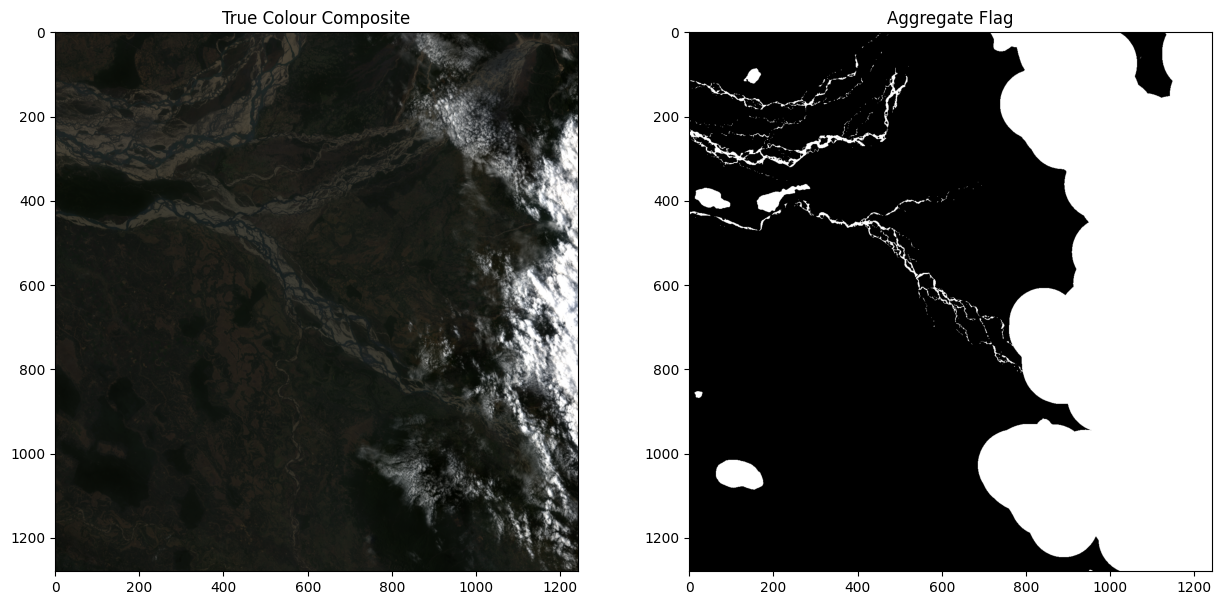

In [47]:
plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)

plt.imshow(
    stretch(img[:, :, [
        band(650),
        band(560),
        band(470)
    ]])
)

plt.title("True Colour Composite")

plt.subplot(1, 2, 2)

plt.imshow(flag, cmap="gray")

plt.title("Aggregate Flag")

plt.show()

In [48]:
print(f"Number of rows    = {img.shape[0]}")
print(f"Number of columns = {img.shape[1]}")
print(f"Number of bands   = {img.shape[2]}")

print("\nWavelengths:")
print(wl)

Number of rows    = 1280
Number of columns = 1242
Number of bands   = 255

Wavelengths:
[ 380.85788  388.26147  395.6681   403.0777   410.49026  417.90585
  425.32443  432.745    440.16953  447.5951   455.0226   462.45114
  469.8827   477.3152   484.7497   492.1852   499.6237   507.0622
  514.5027   521.9432   529.3856   536.8291   544.27356  551.719
  559.16644  566.6139   574.06134  581.5108   588.9602   596.41064
  603.86206  611.3145   618.7669   626.22034  633.67377  641.1282
  648.5826   656.03796  663.4934   670.94977  678.4062   685.8626
  693.32     700.7774   708.2358   715.6932   723.1516   730.61096
  738.0694   745.5288   752.9882   760.4486   767.908    775.3684
  782.8298   790.2902   797.75165  805.21405  812.6754   820.13684
  827.59827  835.0597   842.5221   849.9835   857.446    864.9074
  872.3699   879.8323   887.29376  894.7562   902.2187   909.68115
  917.1436   924.6061   932.06854  939.53107  946.99255  954.455
  961.9165   969.379    976.8406   984.30206  991.

In [49]:
img[500, 600, :]

array([0.03602773, 0.04039154, 0.04680191, 0.04981612, 0.05438428,
       0.05795185, 0.06090833, 0.06296434, 0.06311481, 0.06389699,
       0.06478591, 0.06513147, 0.06432784, 0.06419814, 0.06490831,
       0.06506278, 0.06528185, 0.06661835, 0.06837463, 0.07077496,
       0.07403821, 0.07638703, 0.07752233, 0.07931919, 0.07872787,
       0.07681465, 0.07290364, 0.07188608, 0.07063639, 0.07102647,
       0.07034499, 0.06919087, 0.06755429, 0.06619955, 0.06652556,
       0.0662987 , 0.0642714 , 0.06323733, 0.06130398, 0.06076111,
       0.06130821, 0.06175458, 0.07073821, 0.0855277 , 0.10137337,
       0.11753645, 0.13666444, 0.15570001, 0.17123099, 0.18392853,
       0.19097045, 0.19525628, 0.19879334, 0.2016376 , 0.20398371,
       0.20610902, 0.20821516, 0.21027292, 0.21198927, 0.21392924,
       0.21585785, 0.21778458, 0.21979181, 0.2217191 , 0.22353095,
       0.22533654, 0.22700205, 0.2286069 , 0.23015155, 0.23129071,
       0.23262079, 0.23396273, 0.23528709, 0.236631  , 0.23712

In [50]:
ds

<xarray.Dataset> Size: 2GB
Dimensions:      (downtrack: 1280, crosstrack: 1242, bands: 285)
Dimensions without coordinates: downtrack, crosstrack, bands
Data variables:
    reflectance  (downtrack, crosstrack, bands) float32 2GB ...
Attributes: (12/37)
    ncei_template_version:             NCEI_NetCDF_Swath_Template_v2.0
    summary:                           The Earth Surface Mineral Dust Source ...
    keywords:                          Imaging Spectroscopy, minerals, EMIT, ...
    Conventions:                       CF-1.63
    sensor:                            EMIT (Earth Surface Mineral Dust Sourc...
    instrument:                        EMIT
    ...                                ...
    southernmost_latitude:             27.244149226163522
    spatialResolution:                 0.000542232520256367
    spatial_ref:                       GEOGCS["WGS 84",DATUM["WGS_1984",SPHER...
    geotransform:                      [ 9.51918961e+01  5.42232520e-04 -0.00...
    day_night_flag:                    Day
    title:                             EMIT L2A Estimated Surface Reflectance...

R = band 36 at 648.6 nm, G = band 24 at 559.2 nm, B = band 12 at 469.9 nm


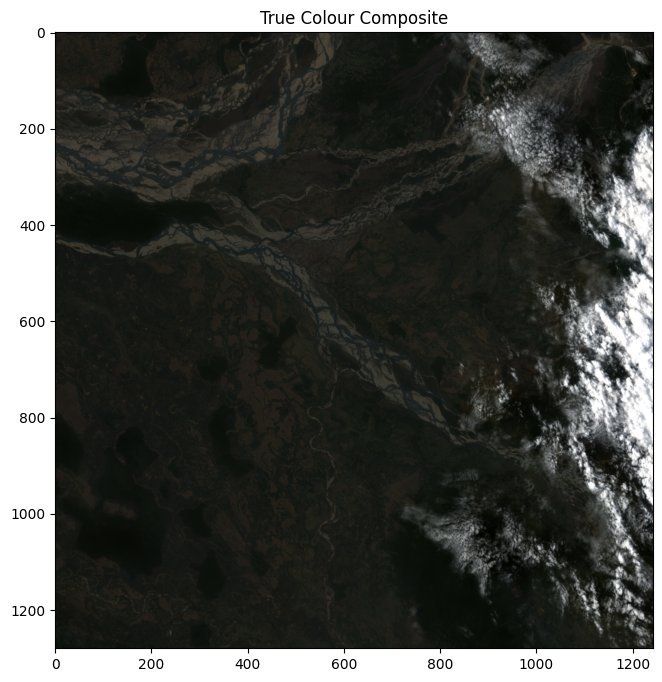

In [51]:
r, g, b = band(650), band(560), band(470)

print(
    f"R = band {r} at {wl[r]:.1f} nm, "
    f"G = band {g} at {wl[g]:.1f} nm, "
    f"B = band {b} at {wl[b]:.1f} nm"
)

plt.figure(figsize=(8, 8))

plt.imshow(stretch(img[:, :, [r, g, b]]))

plt.title("True Colour Composite")
plt.show()

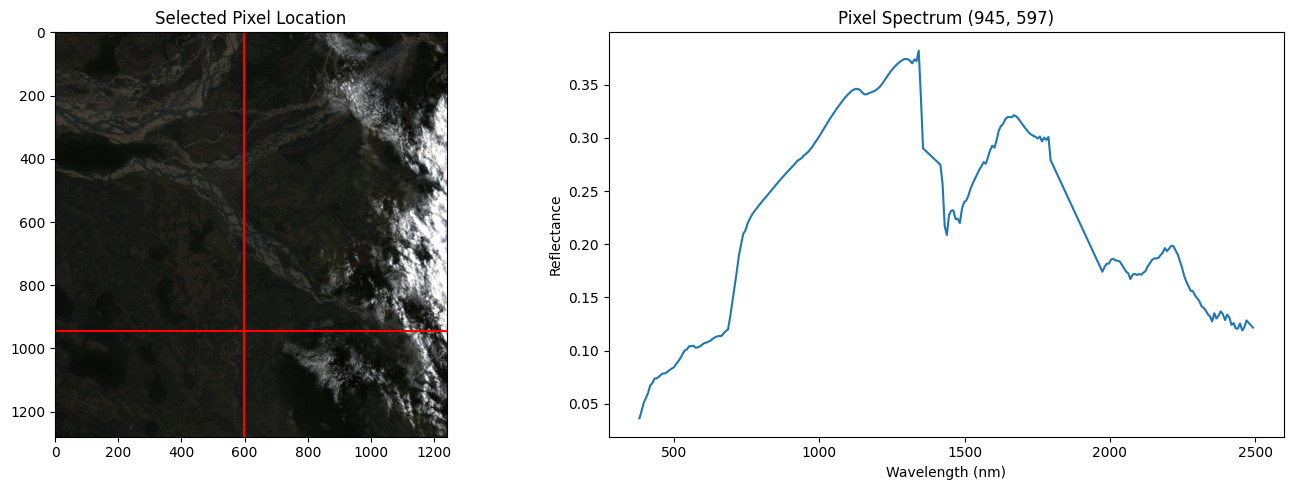

In [52]:
# Select one pixel
row, col = 945, 597

plt.figure(figsize=(14, 5))

# Left: RGB image with selected pixel location
plt.subplot(1, 2, 1)

plt.imshow(
    stretch(img[:, :, [
        band(650),
        band(560),
        band(470)
    ]])
)

plt.axhline(row, color="r")
plt.axvline(col, color="r")

plt.title("Selected Pixel Location")

# Right: Spectral signature
plt.subplot(1, 2, 2)

plt.plot(wl, img[row, col, :])

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.title(f"Pixel Spectrum ({row}, {col})")

plt.tight_layout()
plt.show()

Original cube shape: (128, 128, 255)
Converted matrix shape: (16384, 255)


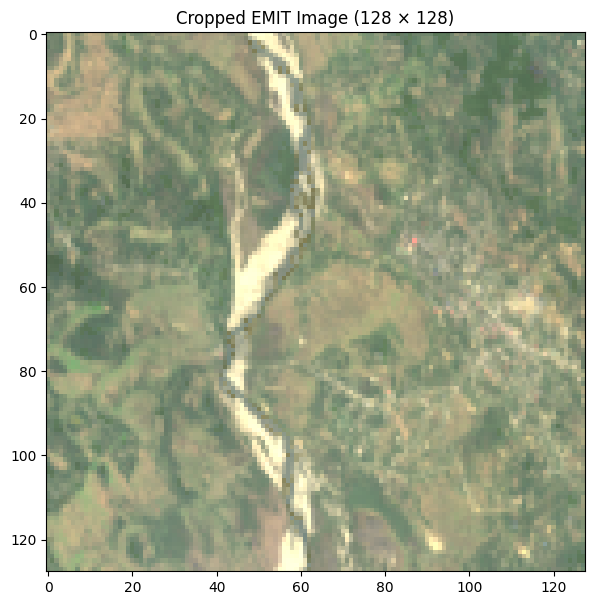

In [53]:
# Select a small region
row0, col0, size = 880, 520, 128

# Extract the hyperspectral cube
cube = img[row0:row0 + size, col0:col0 + size]

# Convert 3D cube into 2D matrix
X = cube.reshape(-1, cube.shape[2])

# Display dimensions
print("Original cube shape:", cube.shape)
print("Converted matrix shape:", X.shape)

# Display cropped RGB image
plt.figure(figsize=(7, 7))

plt.imshow(
    stretch(cube[:, :, [
        band(650),
        band(560),
        band(470)
    ]])
)

plt.title("Cropped EMIT Image (128 × 128)")
plt.show()

Text(0, 0.5, '857 nm')

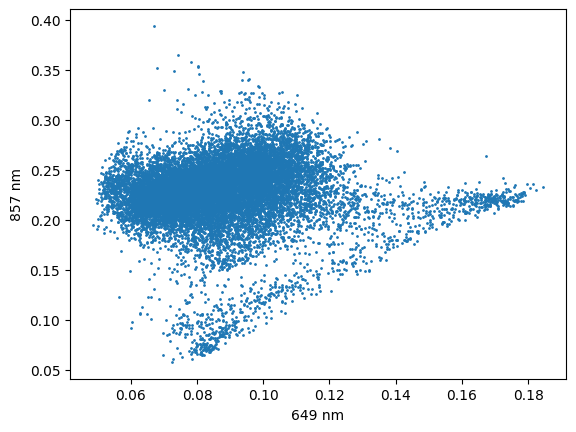

In [54]:
b1, b2 = band(650), band(860)

plt.scatter(X[:, b1], X[:, b2], s=1)

plt.xlabel(f"{wl[b1]:.0f} nm")
plt.ylabel(f"{wl[b2]:.0f} nm")

In [56]:
b1, b2, b3 = band(470), band(650), band(860)

px.scatter_3d(
    x=X[:, b1],
    y=X[:, b2],
    z=X[:, b3],
    height=600,
    labels=dict(
        x=f"{wl[b1]:.0f} nm",
        y=f"{wl[b2]:.0f} nm",
        z=f"{wl[b3]:.0f} nm"
    )
).update_traces(marker_size=1)

Text(0, 0.5, 'Reflectance')

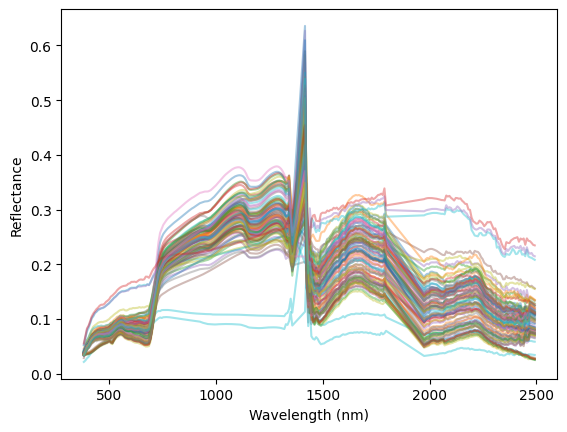

In [57]:
n = 100

idx = np.random.choice(
    len(X), n, replace=False
)

plt.plot(wl, X[idx].T, alpha=0.4)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")

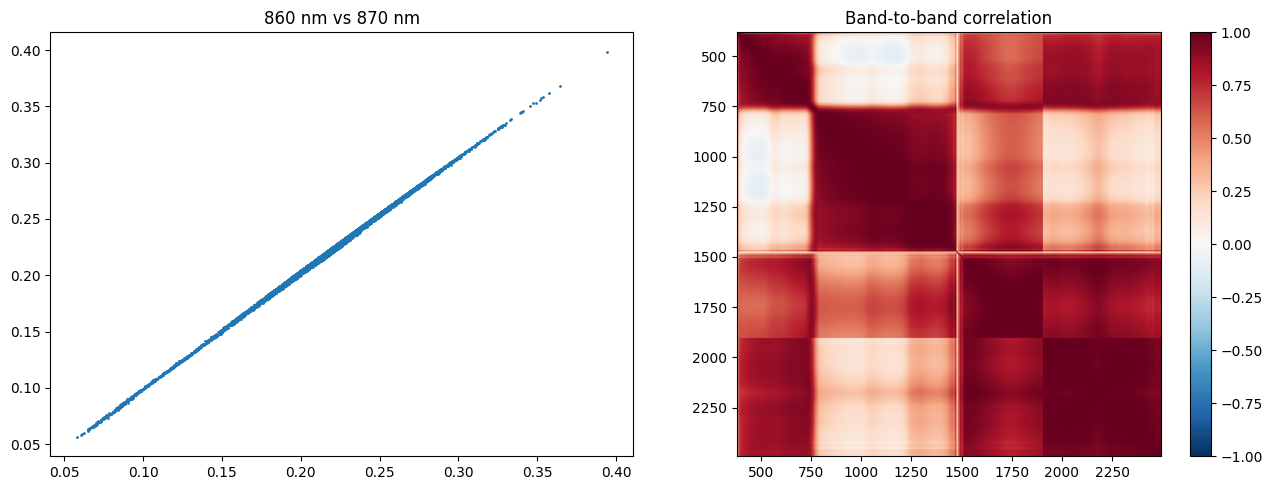

In [58]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    X[:, band(860)],
    X[:, band(870)],
    s=1
)
plt.title("860 nm vs 870 nm")

plt.subplot(1, 2, 2)
plt.imshow(
    np.corrcoef(X.T),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    extent=[wl[0], wl[-1], wl[-1], wl[0]]
)
plt.title("Band-to-band correlation")
plt.colorbar()

plt.tight_layout()
plt.show()

**PCA**

In [61]:

n_pc = 50

pca = PCA(n_components=n_pc).fit(X)

P = pca.transform(X)  # P = (pixels, n_pc)

In [62]:
print("Original data shape:", X.shape)
print("PCA transformed shape:", P.shape)
print("Number of components:", pca.n_components_)

Original data shape: (16384, 255)
PCA transformed shape: (16384, 50)
Number of components: 50


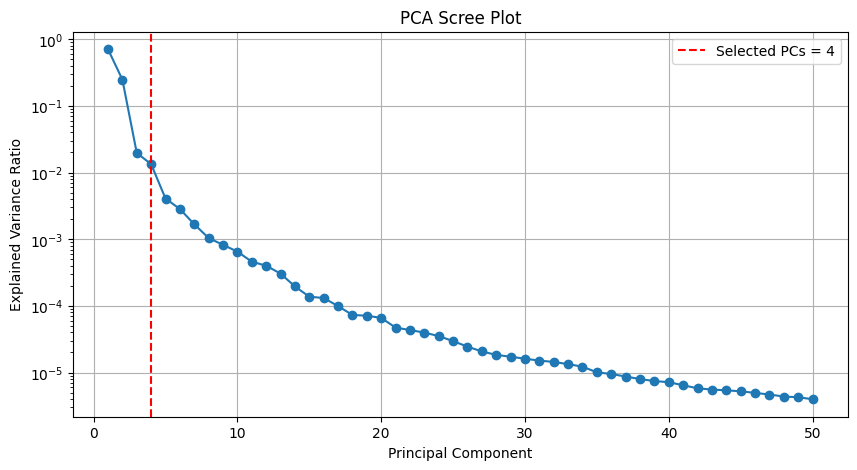

In [68]:
# Scree plot

elbow = 4

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_pc + 1),
    pca.explained_variance_ratio_,
    "o-"
)

plt.yscale("log")

plt.axvline(
    elbow,
    color="red",
    linestyle="--",
    label=f"Selected PCs = {elbow}"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")

plt.legend()
plt.grid(True)

plt.show()

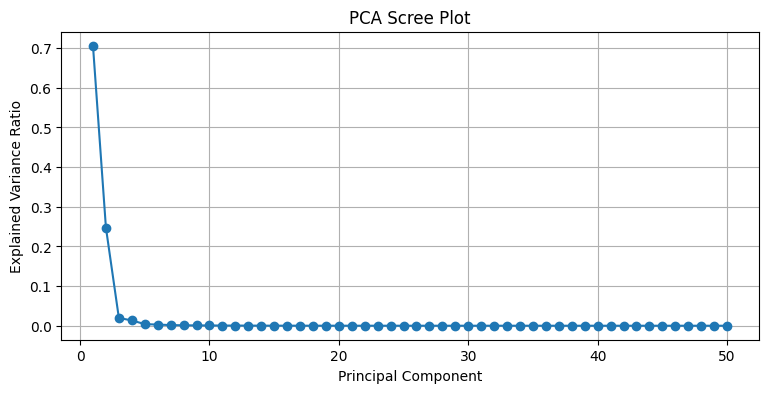

In [63]:
plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(1, n_pc + 1),
    pca.explained_variance_ratio_,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True)

plt.show()

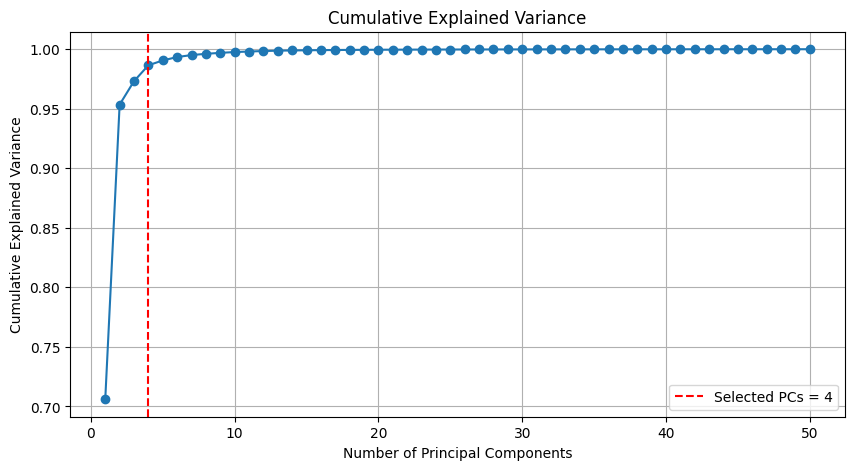

Variance explained by first 4 PCs: 98.64%
Variance explained by first 5 PCs: 99.05%
Variance explained by first 10 PCs: 99.75%


In [69]:
# Cumulative explained variance

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_pc + 1),
    cumulative_variance,
    "o-"
)

plt.axvline(
    elbow,
    color="red",
    linestyle="--",
    label=f"Selected PCs = {elbow}"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("Cumulative Explained Variance")

plt.legend()
plt.grid(True)

plt.show()

print(
    f"Variance explained by first 4 PCs: "
    f"{cumulative_variance[3]*100:.2f}%"
)

print(
    f"Variance explained by first 5 PCs: "
    f"{cumulative_variance[4]*100:.2f}%"
)

print(
    f"Variance explained by first 10 PCs: "
    f"{cumulative_variance[9]*100:.2f}%"
)

In [65]:
print("Variance explained by first 5 PCs:",
      cum_var[4] * 100, "%")

print("Variance explained by first 10 PCs:",
      cum_var[9] * 100, "%")

print("Variance explained by first 20 PCs:",
      cum_var[19] * 100, "%")

print("Variance explained by all 50 PCs:",
      cum_var[-1] * 100, "%")

Variance explained by first 5 PCs: 99.046234 %
Variance explained by first 10 PCs: 99.748535 %
Variance explained by first 20 PCs: 99.94235 %
Variance explained by all 50 PCs: 99.98725 %


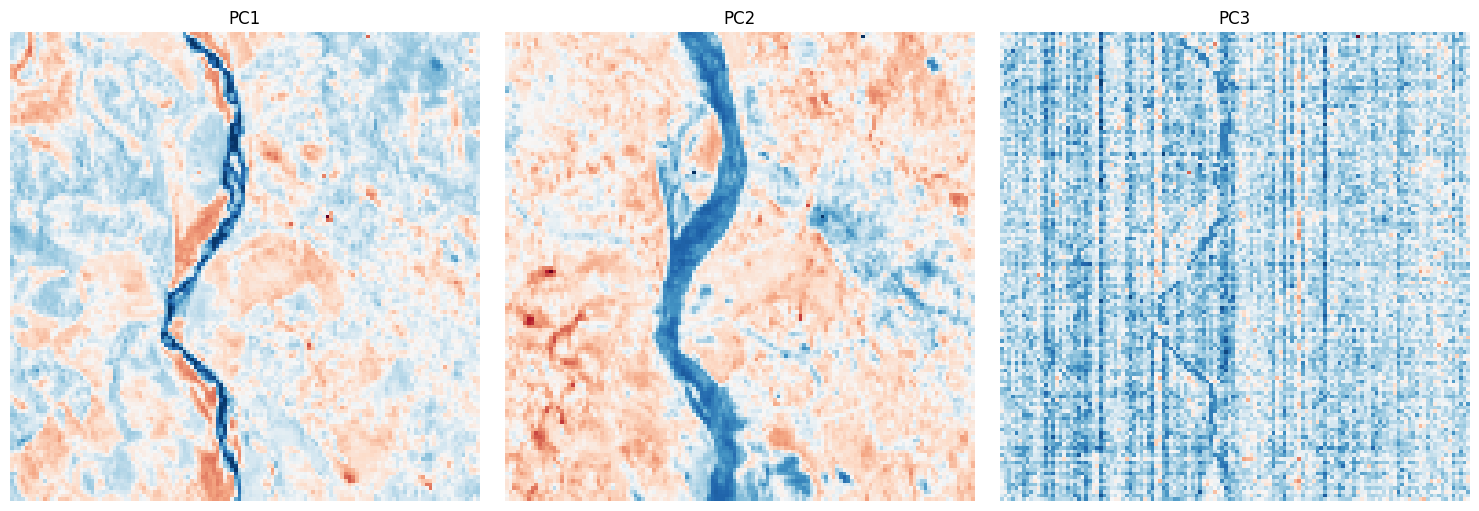

In [66]:
# Reshape PCA scores into spatial images

pc1 = P[:, 0].reshape(128, 128)
pc2 = P[:, 1].reshape(128, 128)
pc3 = P[:, 2].reshape(128, 128)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(pc1, cmap='RdBu_r')
axes[0].set_title('PC1')

axes[1].imshow(pc2, cmap='RdBu_r')
axes[1].set_title('PC2')

axes[2].imshow(pc3, cmap='RdBu_r')
axes[2].set_title('PC3')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

Loading matrix shape: (50, 255)


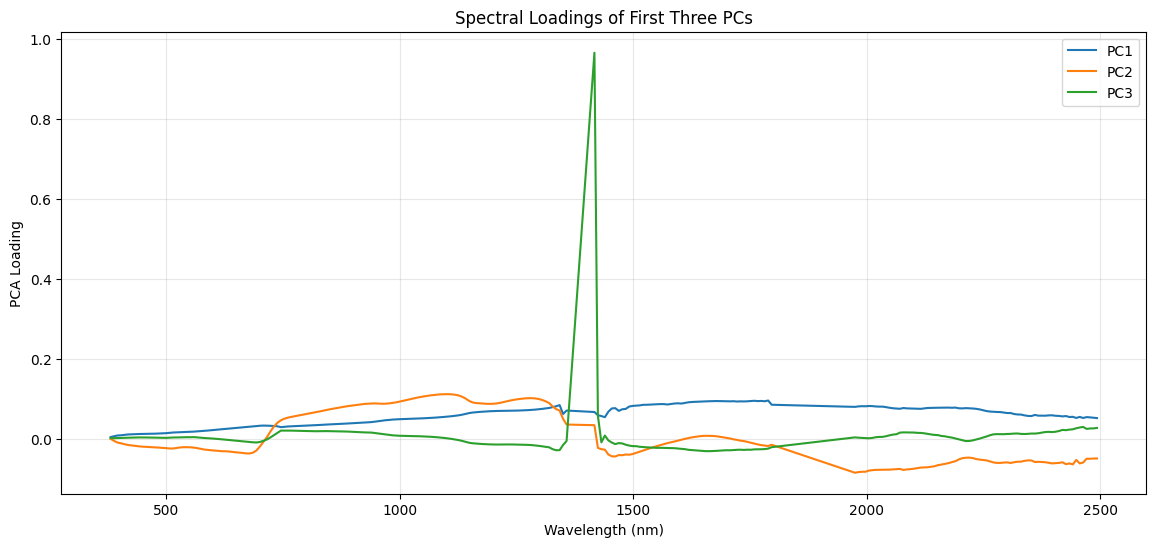

In [67]:
# PCA component loadings

loadings = pca.components_

print("Loading matrix shape:", loadings.shape)

# Plot loadings of first three PCs

plt.figure(figsize=(14, 6))

plt.plot(wl, loadings[0], label="PC1")
plt.plot(wl, loadings[1], label="PC2")
plt.plot(wl, loadings[2], label="PC3")

plt.xlabel("Wavelength (nm)")
plt.ylabel("PCA Loading")
plt.title("Spectral Loadings of First Three PCs")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

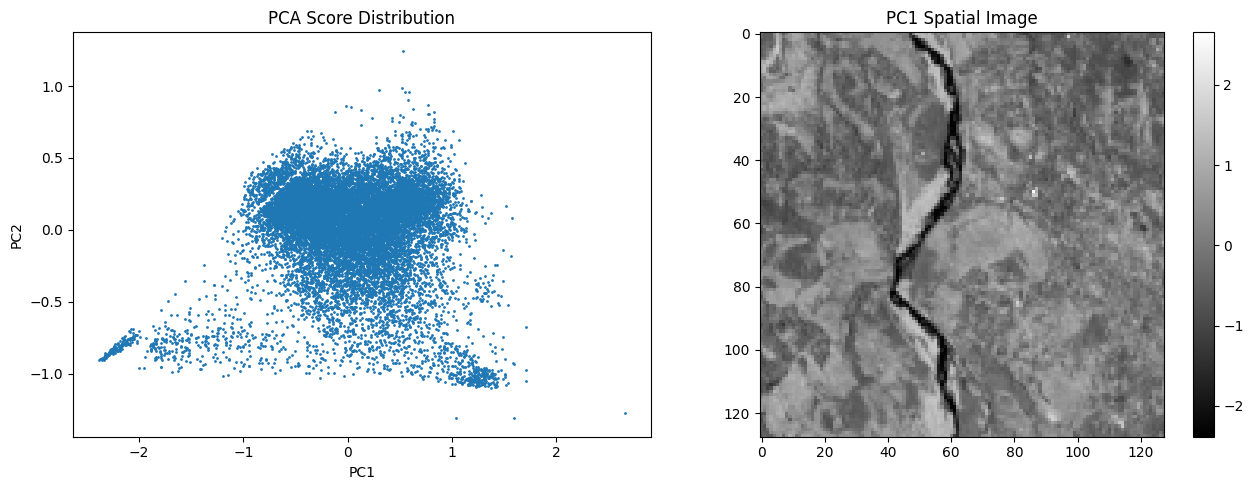

In [70]:
# PCA visualization

pc_a = 0
pc_b = 1

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)

plt.scatter(
    P[:, pc_a],
    P[:, pc_b],
    s=1
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Score Distribution")

plt.subplot(1, 2, 2)

plt.imshow(
    P[:, pc_a].reshape(size, size),
    cmap="gray"
)

plt.title("PC1 Spatial Image")
plt.colorbar()

plt.tight_layout()
plt.show()

In [71]:
# t-SNE parameter selection

n_pcs_used = elbow

perplexity = 30

early_exaggeration = 12

learning_rate = "auto"

max_iter = 1000

init = "pca"

random_state = 0

print("Number of PCs used:", n_pcs_used)
print("Perplexity:", perplexity)
print("Early exaggeration:", early_exaggeration)
print("Learning rate:", learning_rate)
print("Maximum iterations:", max_iter)

Number of PCs used: 4
Perplexity: 30
Early exaggeration: 12
Learning rate: auto
Maximum iterations: 1000


t-SNE output shape: (16384, 2)


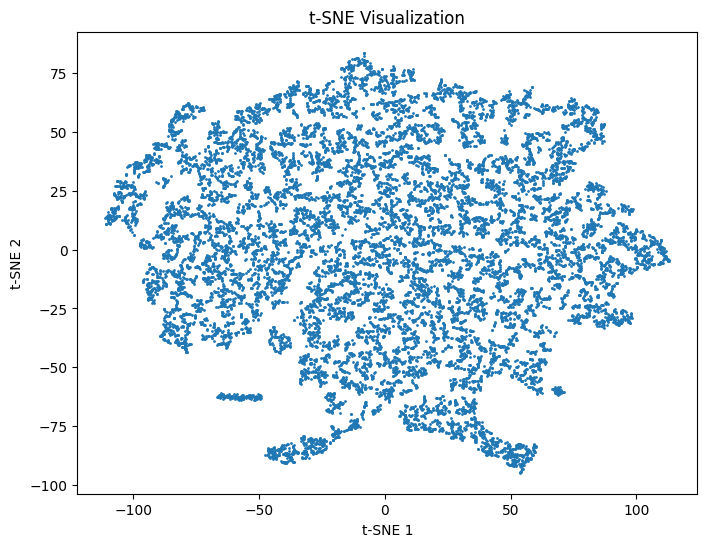

In [72]:
# Apply t-SNE

T = TSNE(
    n_components=2,
    perplexity=perplexity,
    early_exaggeration=early_exaggeration,
    learning_rate=learning_rate,
    max_iter=max_iter,
    init=init,
    random_state=random_state
).fit_transform(P[:, :n_pcs_used])

print("t-SNE output shape:", T.shape)

plt.figure(figsize=(8, 6))

plt.scatter(
    T[:, 0],
    T[:, 1],
    s=1
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.title("t-SNE Visualization")

plt.show()

In [73]:
# K-means clustering

k = 5

labels = KMeans(
    n_clusters=k,
    n_init=10,
    random_state=0
).fit_predict(T)

print("Number of clusters:", k)

print("Cluster distribution:")

print(np.bincount(labels))

Number of clusters: 5
Cluster distribution:
[3711 2799 3558 3505 2811]


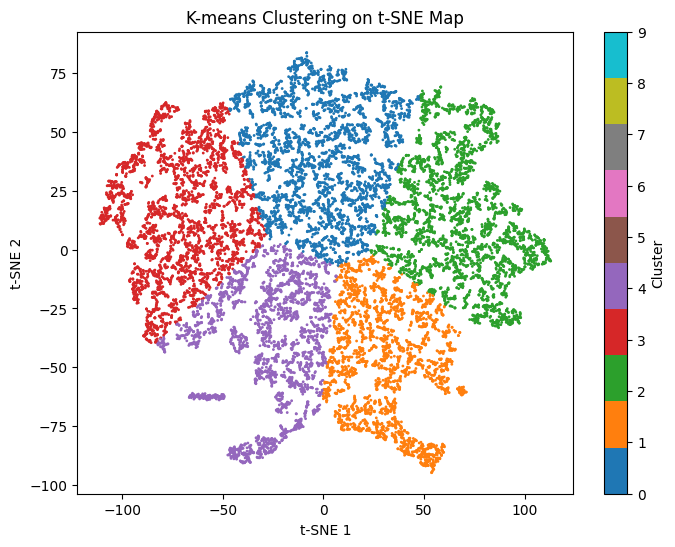

In [74]:
plt.figure(figsize=(8, 6))

plt.scatter(
    T[:, 0],
    T[:, 1],
    s=1,
    c=labels,
    cmap="tab10",
    vmin=0,
    vmax=9
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.title("K-means Clustering on t-SNE Map")

plt.colorbar(label="Cluster")

plt.show()

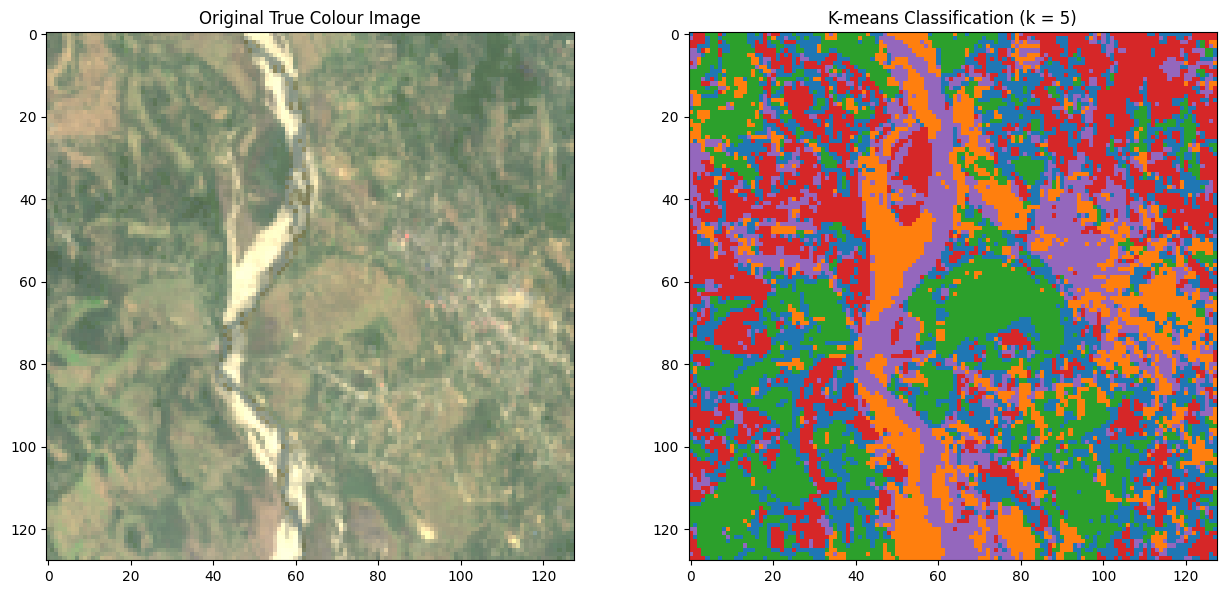

In [75]:
# Original image vs classification image

plt.figure(figsize=(13, 6))

plt.subplot(1, 2, 1)

plt.imshow(
    stretch(cube[:, :, [
        band(650),
        band(560),
        band(470)
    ]])
)

plt.title("Original True Colour Image")

plt.subplot(1, 2, 2)

plt.imshow(
    labels.reshape(size, size),
    cmap="tab10",
    vmin=0,
    vmax=9,
    interpolation="nearest"
)

plt.title(f"K-means Classification (k = {k})")

plt.tight_layout()

plt.show()

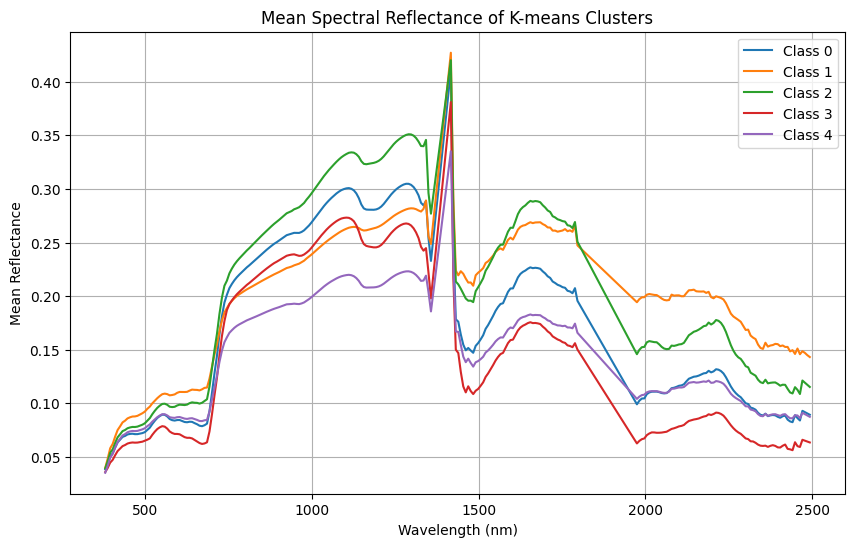

In [76]:
# Mean spectral reflectance of each cluster

plt.figure(figsize=(10, 6))

for i in range(k):

    mean_spectrum = X[labels == i].mean(axis=0)

    plt.plot(
        wl,
        mean_spectrum,
        label=f"Class {i}"
    )

plt.legend()

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean Reflectance")

plt.title("Mean Spectral Reflectance of K-means Clusters")

plt.grid(True)

plt.show()

In [77]:
# Check wavelength regions around 1400 nm and 1900 nm

print("Total spectral bands:", len(wl))

# Identify bands around 1400 nm
region_1400 = np.where(
    (wl >= 1350) & (wl <= 1450)
)[0]

# Identify bands around 1900 nm
region_1900 = np.where(
    (wl >= 1800) & (wl <= 2000)
)[0]

print("\nBands around 1400 nm:")

for i in region_1400:
    print(f"Index: {i}, Wavelength: {wl[i]:.2f} nm")

print("\nBands around 1900 nm:")

for i in region_1900:
    print(f"Index: {i}, Wavelength: {wl[i]:.2f} nm")

Total spectral bands: 255

Bands around 1400 nm:
Index: 131, Wavelength: 1357.19 nm
Index: 132, Wavelength: 1416.80 nm
Index: 133, Wavelength: 1424.25 nm
Index: 134, Wavelength: 1431.69 nm
Index: 135, Wavelength: 1439.14 nm
Index: 136, Wavelength: 1446.59 nm

Bands around 1900 nm:
Index: 184, Wavelength: 1974.53 nm
Index: 185, Wavelength: 1981.95 nm
Index: 186, Wavelength: 1989.37 nm
Index: 187, Wavelength: 1996.79 nm


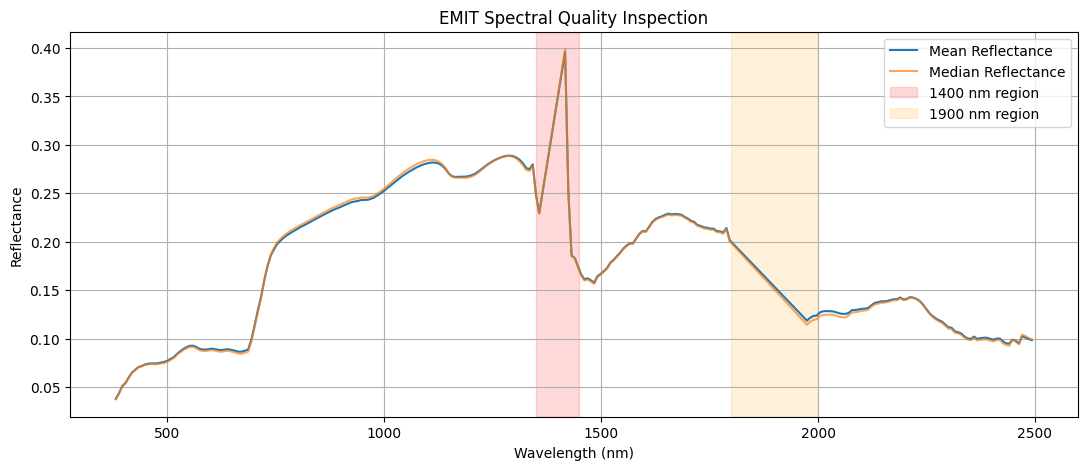

In [78]:
# Calculate mean reflectance of every spectral band

mean_reflectance = np.nanmean(X, axis=0)

median_reflectance = np.nanmedian(X, axis=0)

plt.figure(figsize=(13, 5))

plt.plot(
    wl,
    mean_reflectance,
    label="Mean Reflectance"
)

plt.plot(
    wl,
    median_reflectance,
    label="Median Reflectance",
    alpha=0.7
)

# Highlight absorption regions
plt.axvspan(1350, 1450, color="red", alpha=0.15,
            label="1400 nm region")

plt.axvspan(1800, 2000, color="orange", alpha=0.15,
            label="1900 nm region")

plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")

plt.title("EMIT Spectral Quality Inspection")

plt.legend()
plt.grid(True)

plt.show()

In [79]:
# Examine reflectance values in the selected regions

for name, indices in [
    ("1400 nm region", region_1400),
    ("1900 nm region", region_1900)
]:

    values = X[:, indices]

    print("\n", name)

    print("Mean:", np.nanmean(values))
    print("Median:", np.nanmedian(values))
    print("Minimum:", np.nanmin(values))
    print("Maximum:", np.nanmax(values))
    print("NaN values:", np.isnan(values).sum())


 1400 nm region
Mean: 0.2368694
Median: 0.21403039
Minimum: 0.0
Maximum: 0.7875803
NaN values: 0

 1900 nm region
Mean: 0.12180573
Median: 0.11769349
Minimum: 0.0029112056
Maximum: 0.44473287
NaN values: 0


In [80]:
# Band-wise spectral quality inspection

print("Wavelength spacing analysis")

spacing = np.diff(wl)

print("Median wavelength spacing:",
      np.median(spacing), "nm")

# Identify unusually large gaps
gap_indices = np.where(spacing > 2 * np.median(spacing))[0]

print("\nLarge wavelength gaps:")

for i in gap_indices:
    print(
        f"{wl[i]:.2f} nm to {wl[i+1]:.2f} nm"
    )


# Inspect individual bands
print("\nBand-wise statistics")

for region_name, low, high in [
    ("1400 nm region", 1300, 1500),
    ("1900 nm region", 1750, 2050)
]:

    print("\n", region_name)

    indices = np.where(
        (wl >= low) & (wl <= high)
    )[0]

    for i in indices:

        values = X[:, i]

        print(
            f"Band {i:3d} | "
            f"{wl[i]:8.2f} nm | "
            f"Mean: {np.nanmean(values):.4f} | "
            f"Median: {np.nanmedian(values):.4f} | "
            f"Min: {np.nanmin(values):.4f} | "
            f"Max: {np.nanmax(values):.4f} | "
            f"Zero %: {100*np.mean(values == 0):.2f}%"
        )

Wavelength spacing analysis
Median wavelength spacing: 7.444641 nm

Large wavelength gaps:
1357.19 nm to 1416.80 nm
1796.29 nm to 1974.53 nm

Band-wise statistics

 1400 nm region
Band 124 |  1305.01 nm | Mean: 0.2868 | Median: 0.2857 | Min: 0.0326 | Max: 0.4176 | Zero %: 0.00%
Band 125 |  1312.47 nm | Mean: 0.2843 | Median: 0.2826 | Min: 0.0318 | Max: 0.4173 | Zero %: 0.00%
Band 126 |  1319.92 nm | Mean: 0.2808 | Median: 0.2788 | Min: 0.0308 | Max: 0.4160 | Zero %: 0.00%
Band 127 |  1327.37 nm | Mean: 0.2759 | Median: 0.2739 | Min: 0.0292 | Max: 0.4177 | Zero %: 0.00%
Band 128 |  1334.83 nm | Mean: 0.2750 | Median: 0.2730 | Min: 0.0338 | Max: 0.4221 | Zero %: 0.00%
Band 129 |  1342.28 nm | Mean: 0.2799 | Median: 0.2783 | Min: 0.0309 | Max: 0.4302 | Zero %: 0.00%
Band 130 |  1349.73 nm | Mean: 0.2481 | Median: 0.2473 | Min: 0.0449 | Max: 0.3729 | Zero %: 0.00%
Band 131 |  1357.19 nm | Mean: 0.2295 | Median: 0.2288 | Min: 0.0171 | Max: 0.3725 | Zero %: 0.00%
Band 132 |  1416.80 nm | Mea

In [81]:
# Inspect dataset metadata

print("Dataset variables:")
print(list(ds.data_vars))

print("\nDataset coordinates:")
print(list(ds.coords))

print("\nDataset attributes:")

for key, value in ds.attrs.items():
    print(key, ":", value)

Dataset variables:
['reflectance']

Dataset coordinates:
[]

Dataset attributes:
ncei_template_version : NCEI_NetCDF_Swath_Template_v2.0
summary : The Earth Surface Mineral Dust Source Investigation (EMIT) is an Earth Ventures-Instrument (EVI-4) Mission that maps the surface mineralogy of arid dust source regions via imaging spectroscopy in the visible and short-wave infrared (VSWIR). Installed on the International Space Station (ISS), the EMIT instrument is a Dyson imaging spectrometer that uses contiguous spectroscopic measurements from 410 to 2450 nm to resolve absoprtion features of iron oxides, clays, sulfates, carbonates, and other dust-forming minerals. During its one-year mission, EMIT will observe the sunlit Earth's dust source regions that occur within +/-52° latitude and produce maps of the source regions that can be used to improve forecasts of the role of mineral dust in the radiative forcing (warming or cooling) of the atmosphere.\n\nThis file contains L2A estimated surfa

In [82]:

# ==========================================
# STEP: REMOVE ATMOSPHERIC WATER ABSORPTION BANDS
# ==========================================

# Define problematic wavelength regions
bad_regions = [
    (1350, 1450),   # Around 1400 nm
    (1800, 2000)    # Around 1900 nm
]

# Create a mask for valid wavelengths
valid_bands = np.ones(len(wl), dtype=bool)

for lower, upper in bad_regions:
    valid_bands &= ~((wl >= lower) & (wl <= upper))

# Apply mask to spectral data
X_clean = X[:, valid_bands]

# Apply mask to wavelength array
wl_clean = wl[valid_bands]

# Check results
print("Original spectral data shape:", X.shape)
print("Cleaned spectral data shape:", X_clean.shape)

print("Original number of bands:", len(wl))
print("Remaining number of bands:", len(wl_clean))
print("Removed bands:", np.sum(~valid_bands))

print("\nRemaining wavelength range:")
print("Minimum:", wl_clean.min(), "nm")
print("Maximum:", wl_clean.max(), "nm")


Original spectral data shape: (16384, 255)
Cleaned spectral data shape: (16384, 245)
Original number of bands: 255
Remaining number of bands: 245
Removed bands: 10

Remaining wavelength range:
Minimum: 380.85788 nm
Maximum: 2492.7761 nm


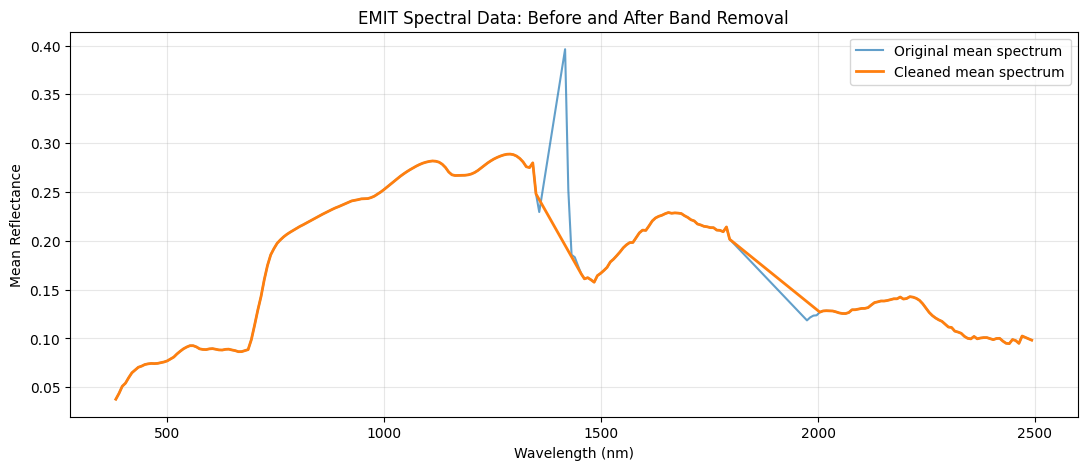

In [83]:

# Mean spectrum before and after cleaning

plt.figure(figsize=(13, 5))

plt.plot(
    wl,
    X.mean(axis=0),
    label="Original mean spectrum",
    alpha=0.7
)

plt.plot(
    wl_clean,
    X_clean.mean(axis=0),
    label="Cleaned mean spectrum",
    linewidth=2
)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean Reflectance")
plt.title("EMIT Spectral Data: Before and After Band Removal")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [84]:

# ==========================================
# PCA ON CLEANED EMIT DATA
# ==========================================

from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Number of principal components
n_pc = 50

# Fit PCA on cleaned data
pca = PCA(n_components=n_pc)

P = pca.fit_transform(X_clean)

# Check dimensions
print("Original cleaned data shape:", X_clean.shape)
print("PCA transformed shape:", P.shape)
print("Number of components:", pca.n_components_)


Original cleaned data shape: (16384, 245)
PCA transformed shape: (16384, 50)
Number of components: 50


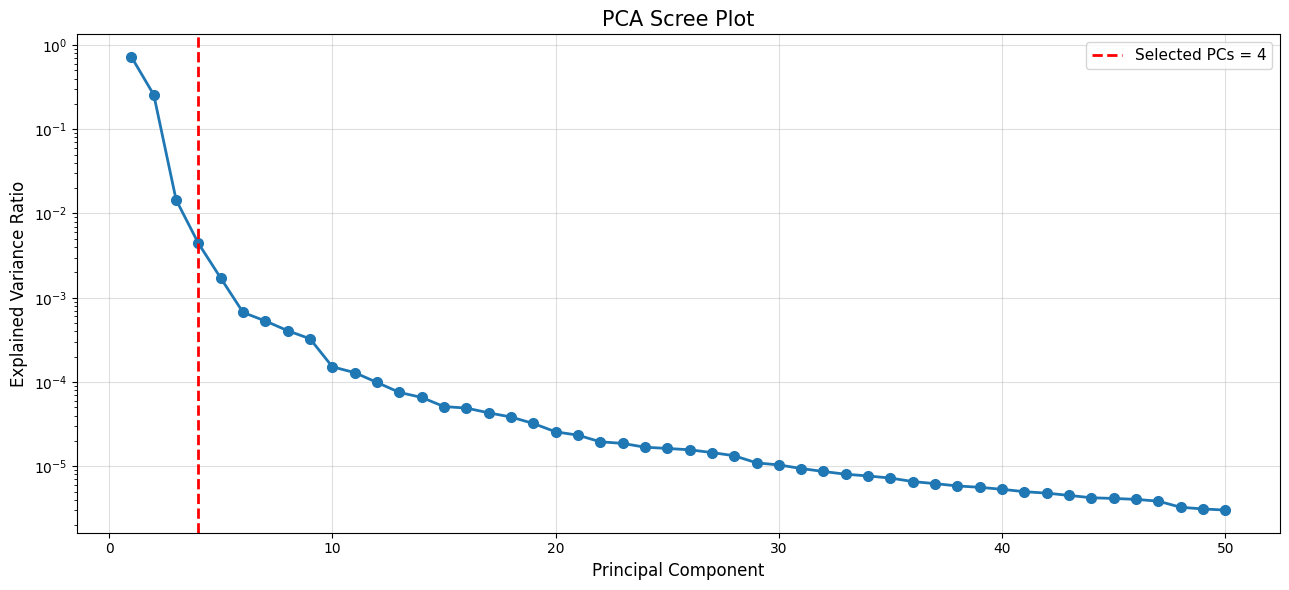

In [102]:
# PCA Scree Plot with selected number of components

elbow = 4

plt.figure(figsize=(13, 6))

plt.plot(
    range(1, n_pc + 1),
    pca.explained_variance_ratio_,
    "o-",
    linewidth=2,
    markersize=7
)

# Logarithmic scale
plt.yscale("log")

# Mark selected PCs
plt.axvline(
    elbow,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Selected PCs = {elbow}"
)

plt.xlabel("Principal Component", fontsize=12)
plt.ylabel("Explained Variance Ratio", fontsize=12)

plt.title(
    "PCA Scree Plot",
    fontsize=15
)

plt.legend(fontsize=11)
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

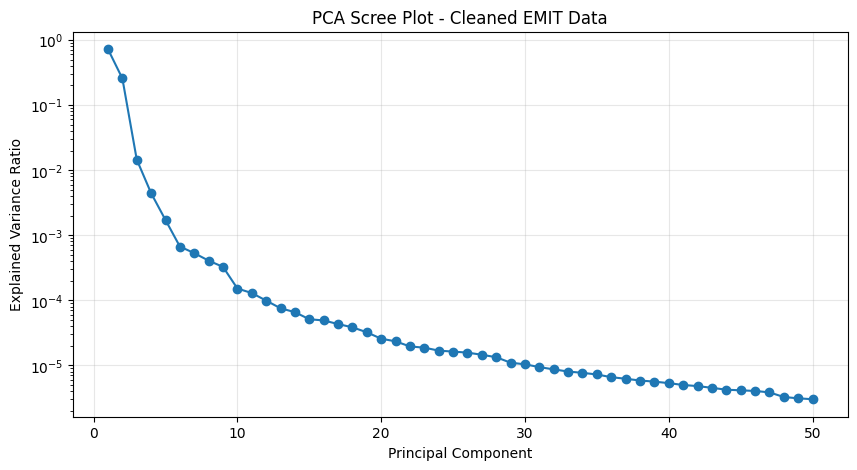

In [85]:

# ==========================================
# PCA SCREE PLOT
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_pc + 1),
    pca.explained_variance_ratio_,
    "o-"
)

plt.yscale("log")

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.title("PCA Scree Plot - Cleaned EMIT Data")

plt.grid(alpha=0.3)
plt.show()


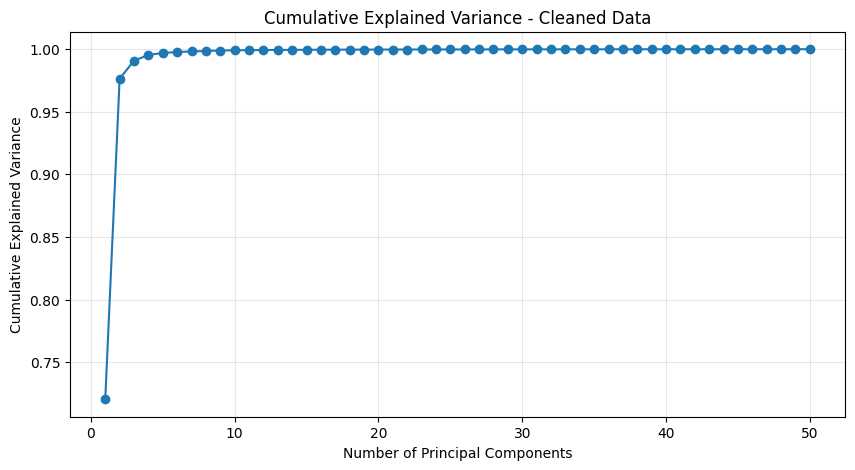

First 3 PCs explain: 99.0799%
First 5 PCs explain: 99.6924%
First 10 PCs explain: 99.9006%
First 20 PCs explain: 99.9615%
First 30 PCs explain: 99.9774%
First 50 PCs explain: 99.9885%


In [86]:

# ==========================================
# CUMULATIVE EXPLAINED VARIANCE
# ==========================================

cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, n_pc + 1),
    cum_var,
    "o-"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("Cumulative Explained Variance - Cleaned Data")

plt.grid(alpha=0.3)
plt.show()

# Print selected values
for n in [3, 5, 10, 20, 30, 50]:
    print(
        f"First {n} PCs explain:",
        f"{cum_var[n-1]*100:.4f}%"
    )


In [87]:
# PCA variance analysis for cleaned EMIT data

print("PCA Variance Analysis")
print("-" * 50)

for i in range(10):
    individual = pca.explained_variance_ratio_[i] * 100
    cumulative = np.sum(pca.explained_variance_ratio_[:i+1]) * 100

    print(
        f"PC{i+1}: "
        f"Individual = {individual:.4f}% | "
        f"Cumulative = {cumulative:.4f}%"
    )

print("-" * 50)

# Selected number of PCs
elbow = 4

print(f"Selected PCs for t-SNE: {elbow}")
print(
    f"Variance retained: "
    f"{np.sum(pca.explained_variance_ratio_[:elbow])*100:.4f}%"
)

PCA Variance Analysis
--------------------------------------------------
PC1: Individual = 72.0401% | Cumulative = 72.0401%
PC2: Individual = 25.5888% | Cumulative = 97.6289%
PC3: Individual = 1.4510% | Cumulative = 99.0799%
PC4: Individual = 0.4416% | Cumulative = 99.5215%
PC5: Individual = 0.1710% | Cumulative = 99.6924%
PC6: Individual = 0.0669% | Cumulative = 99.7593%
PC7: Individual = 0.0530% | Cumulative = 99.8123%
PC8: Individual = 0.0406% | Cumulative = 99.8529%
PC9: Individual = 0.0326% | Cumulative = 99.8855%
PC10: Individual = 0.0151% | Cumulative = 99.9006%
--------------------------------------------------
Selected PCs for t-SNE: 4
Variance retained: 99.5215%


In [88]:
X_work = X.copy()
X_work = X_clean.copy()
import numpy as np
import matplotlib.pyplot as plt

print("Cleaned data shape:", X_work.shape)
print("Number of pixels:", X_work.shape[0])
print("Number of bands:", X_work.shape[1])

size = int(np.sqrt(X_work.shape[0]))

print("Image size:", size, "x", size)

assert size * size == X_work.shape[0], "Image is not square"
assert np.isfinite(X_work).all(), "Data contains NaN or infinite values"

Cleaned data shape: (16384, 245)
Number of pixels: 16384
Number of bands: 245
Image size: 128 x 128


In [89]:
from sklearn.decomposition import PCA

n_pc = 50

pca = PCA(n_components=n_pc)

P = pca.fit_transform(X_work)

print("Original cleaned data shape:", X_work.shape)
print("PCA transformed shape:", P.shape)
print("Number of components:", pca.n_components_)

Original cleaned data shape: (16384, 245)
PCA transformed shape: (16384, 50)
Number of components: 50


In [90]:
elbow = 4

variance = np.sum(
    pca.explained_variance_ratio_[:elbow]
) * 100

print("Selected PCs:", elbow)
print("Variance retained:", variance, "%")

P_selected = P[:, :elbow]

print("Selected PCA data shape:", P_selected.shape)

Selected PCs: 4
Variance retained: 99.52146 %
Selected PCA data shape: (16384, 4)


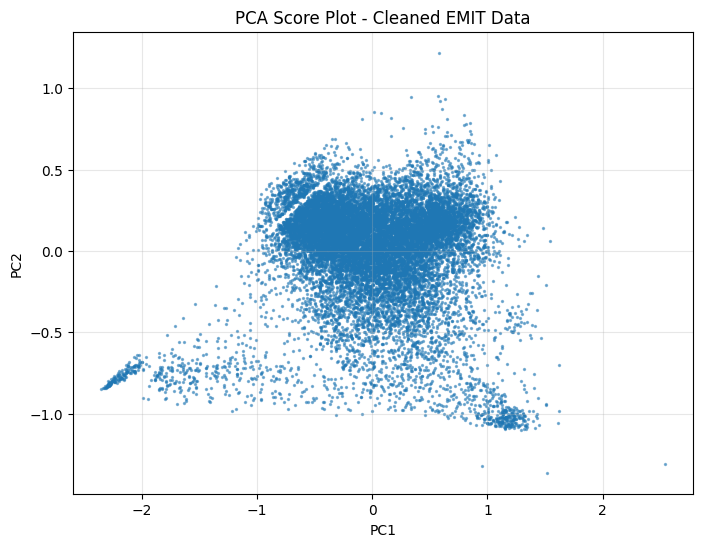

In [91]:
plt.figure(figsize=(8, 6))

plt.scatter(
    P[:, 0],
    P[:, 1],
    s=2,
    alpha=0.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA Score Plot - Cleaned EMIT Data")

plt.grid(alpha=0.3)
plt.show()

In [92]:
from sklearn.manifold import TSNE

n_pcs_used = 4

perplexity = 30
early_exaggeration = 12
learning_rate = "auto"
max_iter = 1000
init = "pca"
random_state = 42

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    early_exaggeration=early_exaggeration,
    learning_rate=learning_rate,
    max_iter=max_iter,
    init=init,
    random_state=random_state
)

T = tsne.fit_transform(P[:, :n_pcs_used])

print("t-SNE output shape:", T.shape)

t-SNE output shape: (16384, 2)


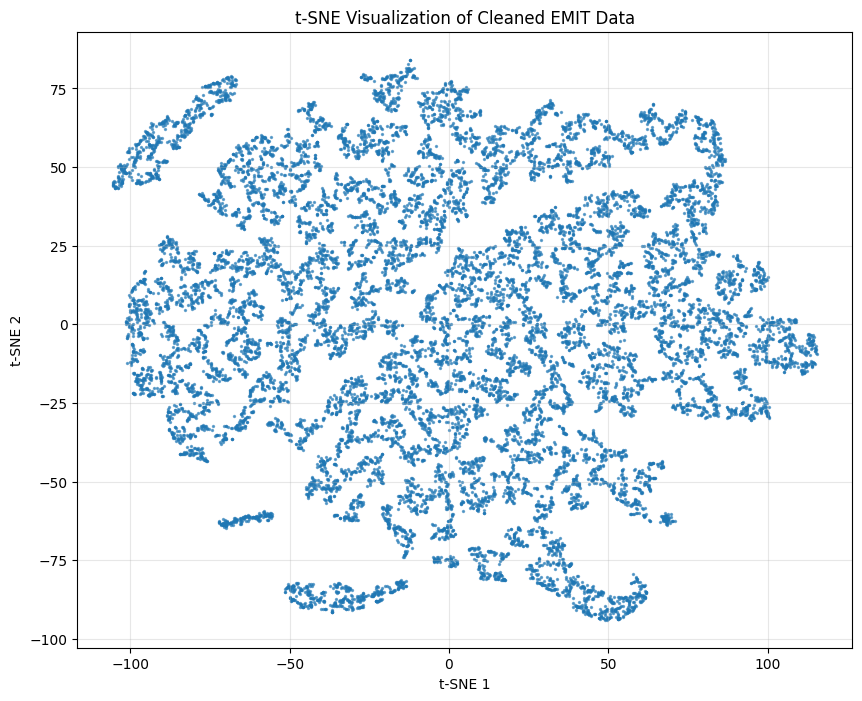

In [93]:
plt.figure(figsize=(10, 8))

plt.scatter(
    T[:, 0],
    T[:, 1],
    s=2,
    alpha=0.6
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.title("t-SNE Visualization of Cleaned EMIT Data")

plt.grid(alpha=0.3)
plt.show()

In [94]:
from sklearn.cluster import KMeans

k = 5

kmeans_tsne = KMeans(
    n_clusters=k,
    n_init=20,
    random_state=42
)

labels_tsne = kmeans_tsne.fit_predict(T)

print("Number of clusters:", k)
print("Cluster labels:", np.unique(labels_tsne))

print("\nPixels in each cluster:")

for i in range(k):
    count = np.sum(labels_tsne == i)
    percentage = count / len(labels_tsne) * 100

    print(
        f"Class {i}: {count} pixels "
        f"({percentage:.2f}%)"
    )

Number of clusters: 5
Cluster labels: [0 1 2 3 4]

Pixels in each cluster:
Class 0: 3403 pixels (20.77%)
Class 1: 3501 pixels (21.37%)
Class 2: 2982 pixels (18.20%)
Class 3: 3534 pixels (21.57%)
Class 4: 2964 pixels (18.09%)


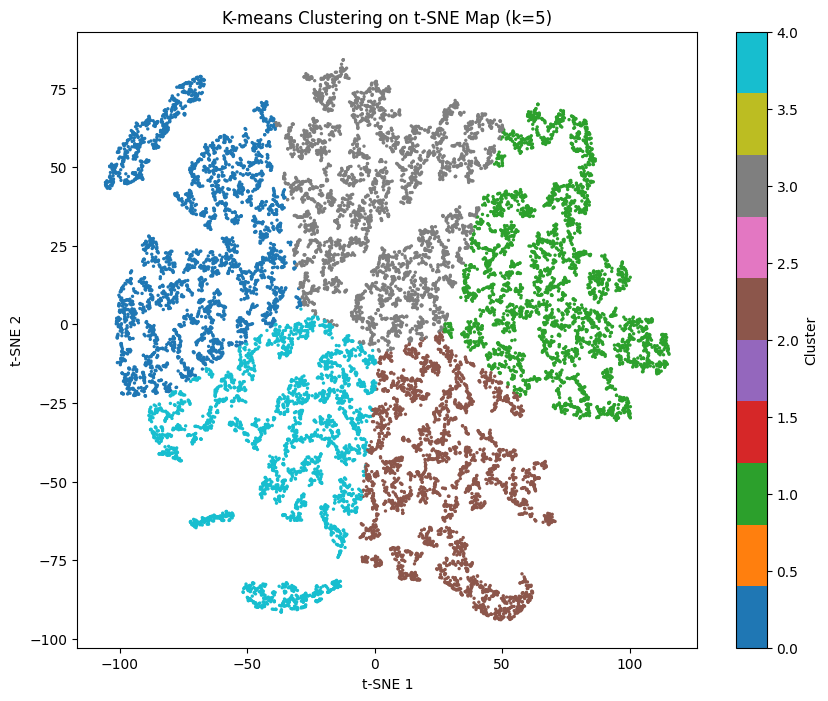

In [95]:
plt.figure(figsize=(10, 8))

plt.scatter(
    T[:, 0],
    T[:, 1],
    s=2,
    c=labels_tsne,
    cmap="tab10",
    vmin=0,
    vmax=k-1
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.title(f"K-means Clustering on t-SNE Map (k={k})")

plt.colorbar(label="Cluster")

plt.show()

In [97]:
# K-means directly on PCA components

kmeans_pca = KMeans(
    n_clusters=k,
    n_init=20,
    random_state=42
)

labels_pca = kmeans_pca.fit_predict(
    P[:, :n_pcs_used]
)

print("PCA clustering completed.")
print("t-SNE clustering completed.")

PCA clustering completed.
t-SNE clustering completed.


In [98]:
from sklearn.metrics import silhouette_score

score_pca = silhouette_score(
    P[:, :n_pcs_used],
    labels_pca
)

score_tsne = silhouette_score(
    P[:, :n_pcs_used],
    labels_tsne
)

print("Silhouette score - K-means on PCA:", score_pca)
print("Silhouette score - K-means on t-SNE:", score_tsne)

Silhouette score - K-means on PCA: 0.3749053
Silhouette score - K-means on t-SNE: 0.2615594


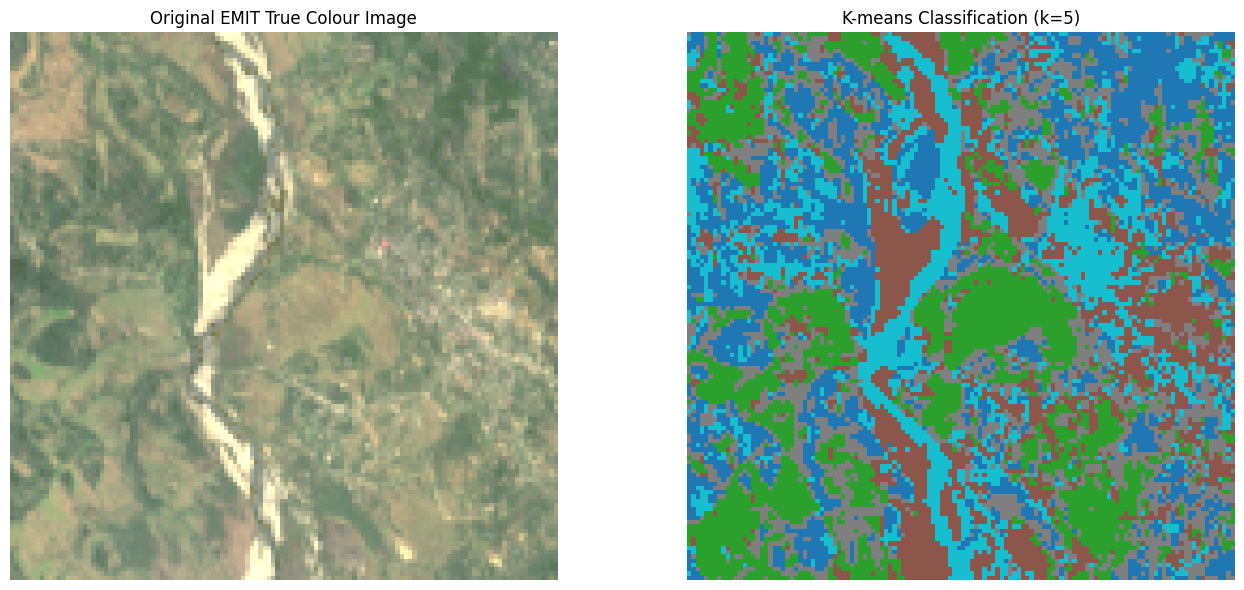

In [99]:
classification_map = labels_tsne.reshape(size, size)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)

plt.imshow(
    stretch(cube[:, :, [
        band(650),
        band(560),
        band(470)
    ]])
)

plt.title("Original EMIT True Colour Image")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    classification_map,
    cmap="tab10",
    vmin=0,
    vmax=k-1,
    interpolation="nearest"
)

plt.title(f"K-means Classification (k={k})")
plt.axis("off")

plt.tight_layout()
plt.show()

In [100]:
# Select the correct cleaned wavelength array

wavelengths = wl_clean.copy()

print("Wavelength shape:", wavelengths.shape)
print("Cleaned data shape:", X_work.shape)

assert len(wavelengths) == X_work.shape[1]

Wavelength shape: (245,)
Cleaned data shape: (16384, 245)


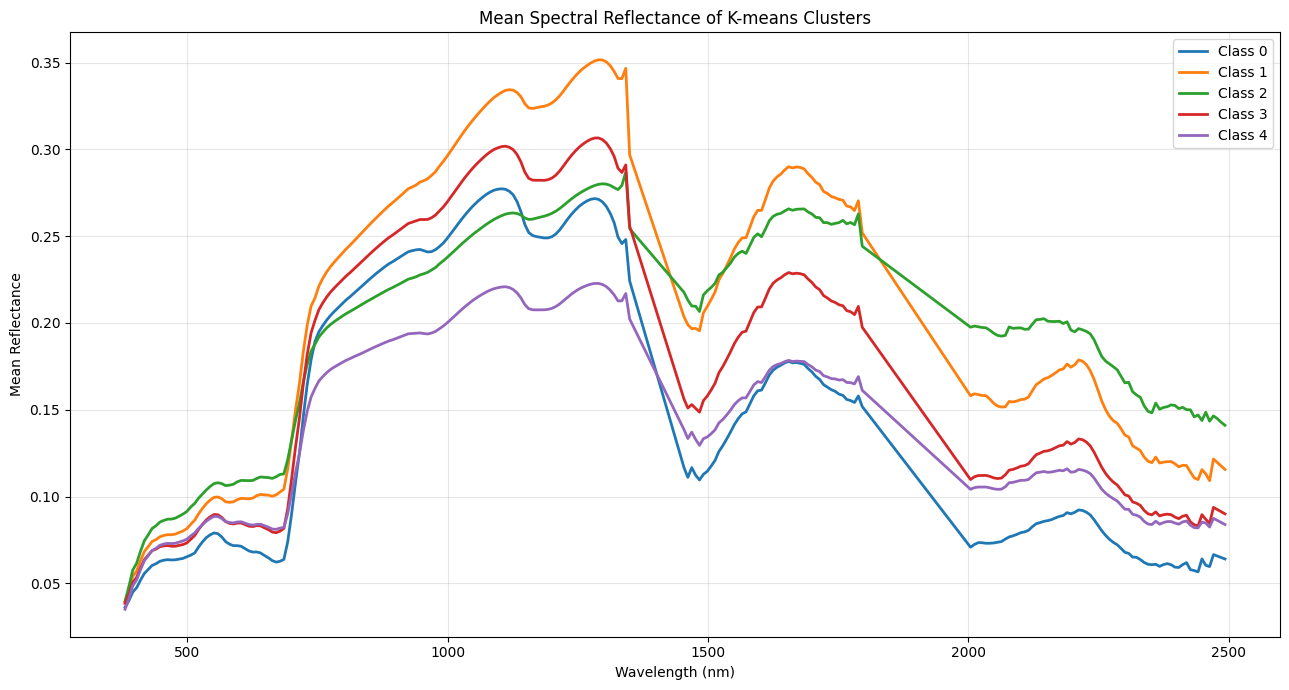

In [101]:
plt.figure(figsize=(13, 7))

for i in range(k):

    mean_spectrum = X_work[
        labels_tsne == i
    ].mean(axis=0)

    plt.plot(
        wavelengths,
        mean_spectrum,
        linewidth=2,
        label=f"Class {i}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Mean Reflectance")

plt.title(
    "Mean Spectral Reflectance of K-means Clusters"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()